# FaceScore：Sparse Score-field Equilibrium (SSE) 对比实验

本 Notebook 的 ours 模型将评分轴 1–10 视为离散一维状态空间。冻结的 TIPSV2 视觉编码器提取图像状态，预测低频离散外场系数，累积为势能并通过 Gibbs 平衡分布得到 10 维评分概率。额外的自由能校正项用于保留强视觉表征中的非对称评分信号。

训练损失同时考虑稀疏评分的 Dirichlet–Multinomial 似然、分布 EMD、评分均值、可靠样本排序、评分人数校正的方差约束和低频力场平滑。所有方法均使用固定 2335/260 划分；基线为冻结官方视觉编码器加统一 10 维分布头，ours 只保存为 `weights/ours.pt`。

本 Notebook 使用 `Python (myenv)` 内核和 CUDA；Cell 12 会缓存 ours 的冻结视觉特征，Cell 14 在已有六个基线完整 200 轮历史时直接复用其权重。


## 1. 环境、路径与超参数
这里预先固定一个实验方案，不在260张验证照片上反复搜索蒸馏系数。代码行之间不留空行。


In [8]:
import random
import re
from decimal import Decimal,ROUND_HALF_UP
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.stats import spearmanr
from torch.utils.data import DataLoader,Dataset,Subset,TensorDataset
from model import SparseLandauScoreField
from others import create_baseline,DistributionLoss
from rating_dataset import RatingDataset
SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP=device.type=='cuda'
NUM_WORKERS=0
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
DATA_DIR=ROOT_DIR/'data/face_data'
MASK_DIR=ROOT_DIR/'data/face_masks'
VALIDATION_FILE=ROOT_DIR/'data/validation_files.txt'
OUTPUT_DIR=ROOT_DIR/'outputs/recent_compare'
WEIGHTS_DIR=ROOT_DIR/'weights'
EPOCHS=200
PATIENCE=40
NLL_PATIENCE=6
MIN_DELTA=1e-5
MICRO_BATCH=8
ACCUM_STEPS=1
LEARNING_RATE=6e-4
WARMUP_EPOCHS=4
WEIGHT_DECAY=0.10
DROPOUT=0.45
EMA_DECAY=0.995
GRAD_CLIP=1.0
BASE_CONCENTRATION=0.1
for folder in (WEIGHTS_DIR,OUTPUT_DIR):
    folder.mkdir(parents=True,exist_ok=True)
print('device:',device,'PyTorch:',torch.__version__)
BASELINE_METHODS=['EUPE','TIPSV2','QWEN35','MOBILECLIP2','PECORE','IFORMER']
BASELINE_EPOCHS=EPOCHS
PLOT_EPOCHS=50
BASELINE_BATCH=16
OURS_FEATURE_BATCH=16
BASELINE_LR=3e-4
print('method: sparse score-field equilibrium head on frozen TIPSV2 features')


device: cuda PyTorch: 2.10.0+cu128
method: sparse score-field equilibrium head on frozen TIPSV2 features


## 2. 严格使用之前的固定2335/260划分
不自动重新随机切分。标签仍是 `[B,10]` 的经验分布。


In [9]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'图像目录不存在：{DATA_DIR.resolve()}')
if not VALIDATION_FILE.is_file():
    raise FileNotFoundError('缺少data/validation_files.txt，请确认固定验证集清单')
mask_dir=str(MASK_DIR) if MASK_DIR.is_dir() else None
base_dataset=RatingDataset(str(DATA_DIR),mask_dir=mask_dir,augment=False,repeat=1,image_size=336,soft_target=False)
image_names=[path.name for path in base_dataset.image_paths]
if len(set(image_names))!=len(image_names):
    raise RuntimeError('数据集存在重复文件名')
val_names={Path(line.strip()).name for line in VALIDATION_FILE.read_text(encoding='utf-8-sig').splitlines() if line.strip()}
if not val_names.issubset(set(image_names)):
    raise RuntimeError(f'验证清单缺失图像：{sorted(val_names-set(image_names))[:10]}')
train_ids=[i for i,name in enumerate(image_names) if name not in val_names]
val_ids=[i for i,name in enumerate(image_names) if name in val_names]
if (len(train_ids),len(val_ids))!=(2335,260):
    raise RuntimeError(f'当前划分为{len(train_ids)}/{len(val_ids)}，预期2335/260，请核对数据和清单')
eval_train_dataset=Subset(base_dataset,train_ids)
val_dataset=Subset(base_dataset,val_ids)
def parse_scores(path):
    content=path.with_suffix('.txt').read_text(encoding='utf-8-sig').strip().removeprefix('[').removesuffix(']')
    words=[word for word in re.split(r'[,，\s]+',content) if word]
    scores=[int(max(Decimal(1),min(Decimal(10),Decimal(word))).quantize(Decimal(1),rounding=ROUND_HALF_UP)) for word in words]
    if not scores:
        raise RuntimeError(f'照片缺少评分：{path}')
    return scores
train_counts=[]
train_targets=[]
for idx in train_ids:
    scores=parse_scores(base_dataset.image_paths[idx])
    counts=torch.bincount(torch.tensor(scores,dtype=torch.long)-1,minlength=10).float()
    train_targets.append(counts/counts.sum().clamp_min(1e-8))
    train_counts.append(len(scores))
train_targets=torch.stack(train_targets)
train_counts=torch.tensor(train_counts,dtype=torch.float32)
prior_counts=(train_targets*train_counts.view(-1,1)).sum(dim=0)
prior=prior_counts/train_counts.sum().clamp_min(1.0)
val_counts=[]
val_targets=[]
for idx in val_ids:
    scores=parse_scores(base_dataset.image_paths[idx])
    counts=torch.bincount(torch.tensor(scores,dtype=torch.long)-1,minlength=10).float()
    val_targets.append(counts/counts.sum().clamp_min(1e-8))
    val_counts.append(len(scores))
val_targets=torch.stack(val_targets)
val_counts=torch.tensor(val_counts,dtype=torch.float32)
train_dataset=Subset(base_dataset,train_ids)
print('训练图像:',len(train_ids),'验证图像:',len(val_ids))
print('训练集单评分照片:',int((train_counts==1).sum()))
print('训练集原始先验:',prior.numpy().round(4).tolist())


训练图像: 2335 验证图像: 260
训练集单评分照片: 969
训练集原始先验: [0.027899999171495438, 0.05999999865889549, 0.15459999442100525, 0.22040000557899475, 0.19629999995231628, 0.1655000001192093, 0.10249999910593033, 0.041099999099969864, 0.021800000220537186, 0.00989999994635582]


## 4. 离散平衡力场分布头

评分分布由图像条件离散外场产生：相邻评分边界上的低频力经累积得到势能，随后以先验评分分布和温度构成 Gibbs 平衡态。这个参数化允许评分偏斜和高分尾部变化，同时用低频基展开限制稀疏标签下的过拟合。自由能校正项直接作用于冻结 TIPSV2 表征，补偿仅靠低阶力场无法表达的视觉排序信息。


## 4. 数据加载、评价指标与 EMA


In [10]:
class CountDataset(Dataset):
    def __init__(self,dataset,counts,raw_targets):
        self.dataset=dataset
        self.counts=counts
        self.raw_targets=raw_targets
        if len(dataset)!=len(counts) or len(dataset)!=len(raw_targets):
            raise ValueError('图像数量与评分人数数量不一致')
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self,index):
        x,y=self.dataset[index]
        return x,y,self.counts[index],self.raw_targets[index]
count_train_dataset=CountDataset(train_dataset,train_counts,train_targets)
train_loader=DataLoader(count_train_dataset,batch_size=128,shuffle=True,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
val_loader=DataLoader(val_dataset,batch_size=128,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
eval_train_loader=DataLoader(eval_train_dataset,batch_size=BASELINE_BATCH,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
baseline_val_loader=DataLoader(val_dataset,batch_size=BASELINE_BATCH,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
def compute_metrics(probs,targets):
    p=np.asarray(probs,dtype=np.float64)
    y=np.asarray(targets,dtype=np.float64)
    if p.shape!=y.shape or p.ndim!=2 or p.shape[1]!=10:
        raise RuntimeError('预测与标签必须为[N,10]')
    p=np.maximum(p,1e-12)
    p=p/p.sum(axis=1,keepdims=True)
    bins=np.arange(1,11,dtype=np.float64)
    mean_p=p@bins
    mean_y=y@bins
    rho=spearmanr(mean_p,mean_y).statistic
    return {'emd':float(np.sqrt(np.square(np.cumsum(p,axis=1)-np.cumsum(y,axis=1)).mean(axis=1)).mean()),'mae':float(np.abs(mean_p-mean_y).mean()),'nll':float(-(y*np.log(p)).sum(axis=1).mean()),'spearman':float(rho)}
class TrainableEMA:
    def __init__(self,model,decay=0.995):
        self.decay=float(decay)
        self.shadow={name:param.detach().clone() for name,param in model.named_parameters() if param.requires_grad}
        self.backup={}
    @torch.no_grad()
    def update(self,model):
        for name,param in model.named_parameters():
            if param.requires_grad:
                self.shadow[name].lerp_(param.detach(),1.0-self.decay)
    @torch.no_grad()
    def apply(self,model):
        if self.backup:
            raise RuntimeError('EMA当前状态未恢复')
        for name,param in model.named_parameters():
            if param.requires_grad:
                self.backup[name]=param.detach().clone()
                param.copy_(self.shadow[name])
    @torch.no_grad()
    def restore(self,model):
        for name,param in model.named_parameters():
            if name in self.backup:
                param.copy_(self.backup[name])
        self.backup.clear()
def save_model(model,path):
    torch.save({name:tensor.detach().cpu() for name,tensor in model.state_dict().items()},path)
def select_score(metrics):
    return 0.25*metrics['emd']/0.23+0.025*metrics['mae']/1.13+0.45*metrics['nll']/1.84+0.275*(1.0-metrics['spearman'])/0.45


## 5. Dirichlet–Multinomial 训练目标
Landau 自由能评分轴将 1–10 分建模为有序状态，图像特征预测均值场、曲率、尾部场和温度参数。原始评分计数通过按评分人数归一化的 Dirichlet–Multinomial 后验监督，并联合 EMD、均值、排序和熵校准约束。


In [11]:
loss_fn=DistributionLoss(prior=prior,alpha=BASE_CONCENTRATION,dm_weight=0.02,ce_weight=0.50,emd_weight=1.00,mean_weight=1.00,rank_weight=0.20,rank_temperature=0.30,rdrop_weight=0.02,tail_weight=0.05,tail_margin=0.02,target_smoothing=0.35,entropy_weight=0.02,count_weight_power=0.25,count_weight_max=1.5,dm_per_rating=True,spread_weight=0.05,field_smooth_weight=0.002).to(device)
def train_epoch(model,optimizer,scaler,ema):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    predictions=[]
    labels=[]
    objective_total=0.0
    seen=0
    trainable=[param for param in model.parameters() if param.requires_grad]
    for step,(x,y,count,raw_y) in enumerate(train_loader):
        x=x.to(device,non_blocking=True)
        y=y.to(device,non_blocking=True).float()
        count=count.to(device,non_blocking=True).float().clamp_min(1.0)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            outputs,concentrations=model(x,return_pair=True,return_evidence=True)
            base_loss=loss_fn(outputs,y,count,concentrations)
        student_logp=outputs[0].float()
        window_start=(step//ACCUM_STEPS)*ACCUM_STEPS
        window_size=min(ACCUM_STEPS,len(train_loader)-window_start)
        if scaler is None:
            (base_loss/window_size).backward()
        else:
            scaler.scale(base_loss/window_size).backward()
        update_now=(step+1)%ACCUM_STEPS==0 or step+1==len(train_loader)
        if update_now:
            if scaler is not None:
                scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable,max_norm=GRAD_CLIP)
            if scaler is None:
                optimizer.step()
                successful_step=True
            else:
                previous_scale=scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                successful_step=scaler.get_scale()>=previous_scale
            if successful_step:
                ema.update(model)
            optimizer.zero_grad(set_to_none=True)
        n=len(y)
        predictions.append(student_logp.detach().exp().cpu())
        labels.append(raw_y.detach().float().cpu())
        objective_total+=float(base_loss.detach())*n
        seen+=n
    result=compute_metrics(torch.cat(predictions).numpy(),torch.cat(labels).numpy())
    result['loss']=objective_total/seen
    return result
@torch.inference_mode()
def evaluate_epoch(model):
    model.eval()
    predictions=[]
    labels=[]
    total_loss=0.0
    seen=0
    for batch in val_loader:
        x=batch[0].to(device,non_blocking=True)
        y=batch[1].to(device,non_blocking=True).float()
        count=torch.tensor([len(parse_scores(base_dataset.image_paths[val_ids[seen+i]])) for i in range(len(y))],device=device,dtype=torch.float32)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            output,concentration=model(x,return_evidence=True)
            supervised_loss=loss_fn(output,y,count,concentration)
        predictions.append(output.float().exp().cpu())
        labels.append(y.float().cpu())
        total_loss+=float(supervised_loss.detach())*len(y)
        seen+=len(y)
    result=compute_metrics(torch.cat(predictions).numpy(),torch.cat(labels).numpy())
    result['loss']=total_loss/seen
    return result


In [12]:
def baseline_objective(log_probs,target):
    probs=log_probs.float().exp().clamp_min(1e-8)
    target=target.float().clamp_min(0.0)
    target=target/target.sum(dim=1,keepdim=True).clamp_min(1e-8)
    nll=-(target*log_probs.float()).sum(dim=1).mean()
    emd=torch.sqrt((probs.cumsum(dim=1)-target.cumsum(dim=1)).square().mean(dim=1).clamp_min(1e-8)).mean()
    bins=torch.arange(1,11,device=probs.device,dtype=probs.dtype).view(1,10)
    mean_loss=torch.nn.functional.smooth_l1_loss((probs*bins).sum(dim=1),(target*bins).sum(dim=1),beta=1.0)/9.0
    return 0.5*nll+1.0*emd+1.0*mean_loss
@torch.inference_mode()
def extract_baseline_features(net,dataset):
    loader=DataLoader(dataset,batch_size=BASELINE_BATCH,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
    features=[]
    labels=[]
    net.eval()
    for x,y in loader:
        x=x.to(device,non_blocking=True)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            feature=net.extract_features(x)
        features.append(feature.float().cpu())
        labels.append(y.float().cpu())
    return torch.cat(features),torch.cat(labels)
def baseline_metrics(net,features,targets):
    predictions=[]
    total_loss=0.0
    total_count=0
    net.eval()
    with torch.inference_mode():
        for start in range(0,len(features),BASELINE_BATCH):
            end=min(start+BASELINE_BATCH,len(features))
            batch_features=features[start:end].to(device,non_blocking=True)
            batch_targets=targets[start:end].to(device,non_blocking=True)
            log_probs=net.forward_from_features(batch_features).float()
            predictions.append(log_probs.exp().cpu())
            total_loss+=float(baseline_objective(log_probs,batch_targets))*len(batch_targets)
            total_count+=len(batch_targets)
    metrics=compute_metrics(torch.cat(predictions).numpy(),targets.numpy())
    metrics['loss']=total_loss/max(1,total_count)
    return metrics


## 6. 训练 ours 与六个冻结编码器基线
Notebook 保存唯一的 weights/ours.pt，以及 EUPE.pt、TIPSV2.pt、QWEN35.pt、MOBILECLIP2.pt、PECORE.pt、IFORMER.pt。


In [14]:
class FrozenEncoderTokenAdapter(torch.nn.Module):
    def __init__(self,encoder,input_size,mean,std):
        super().__init__()
        self.encoder=encoder
        self.embed_dim=int(encoder.num_features)
        self.global_only=True
        self.input_size=int(input_size)
        self.register_buffer('mean',mean.detach().clone())
        self.register_buffer('std',std.detach().clone())
    def get_intermediate_layers(self,x,n=3,return_class_token=True,norm=True):
        features=self.encoder(x)
        tokens=features.unsqueeze(1)
        return [(tokens,features) for _ in range(3)]
    def train(self,mode=True):
        super().train(mode)
        self.encoder.eval()
        return self
tip_encoder=create_baseline('TIPSV2',pretrained=True,freeze_backbone=True,dropout=0.0)
tip_adapter=FrozenEncoderTokenAdapter(tip_encoder.backbone,tip_encoder.input_size,tip_encoder.mean,tip_encoder.std)
student=SparseLandauScoreField(pretrained=False,backbone=tip_adapter,dropout=0.10,train_last_stage=False,width=24,prior_mix=0.0,use_entropy=False,use_high_resolution=False,scales=(224,),grid_side=16,use_evidence_head=True,evidence_base=BASE_CONCENTRATION,use_global_token=True).to(device)
student.mean.copy_(tip_adapter.mean)
student.std.copy_(tip_adapter.std)
@torch.inference_mode()
def extract_ours_features(dataset):
    loader=DataLoader(dataset,batch_size=OURS_FEATURE_BATCH,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
    chunks=[]
    student.eval()
    for batch in loader:
        inputs=batch[0].to(device,non_blocking=True)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            features=student.encode_features(inputs)
        chunks.append(features.float().cpu())
    return torch.cat(chunks,dim=0)
train_feature_values=extract_ours_features(eval_train_dataset)
val_feature_values=extract_ours_features(val_dataset)
student.set_feature_stats(train_feature_values.mean(dim=0),train_feature_values.std(dim=0))
train_feature_dataset=TensorDataset(train_feature_values,train_targets)
val_feature_dataset=TensorDataset(val_feature_values,val_targets)
count_train_dataset=CountDataset(train_feature_dataset,train_counts,train_targets)
train_loader=DataLoader(count_train_dataset,batch_size=128,shuffle=True,num_workers=0,pin_memory=USE_AMP)
val_loader=DataLoader(val_feature_dataset,batch_size=128,shuffle=False,num_workers=0,pin_memory=USE_AMP)
student.set_prior(prior)
decay_parameters=[]
no_decay_parameters=[]
prediction_decay_parameters=[]
prediction_no_decay_parameters=[]
for name,param in student.named_parameters():
    if not param.requires_grad:
        continue
    is_prediction=any(key in name.lower() for key in ('head','evidence','global_projection','global_gate'))
    is_no_decay=param.ndim<2 or any(key in name.lower() for key in ('bias','norm','source_scale','source_bias','scale_logits','entropy_log_scale','evidence_gate','local_evidence_logit','global_gate'))
    if is_prediction and is_no_decay:
        prediction_no_decay_parameters.append(param)
    elif is_prediction:
        prediction_decay_parameters.append(param)
    elif is_no_decay:
        no_decay_parameters.append(param)
    else:
        decay_parameters.append(param)
optimizer=torch.optim.AdamW([{'params':decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':WEIGHT_DECAY},{'params':no_decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':0.0},{'params':prediction_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':WEIGHT_DECAY*0.5},{'params':prediction_no_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':0.0}],lr=LEARNING_RATE)
def schedule_lambda(epoch):
    if epoch<WARMUP_EPOCHS:
        return 0.3+0.7*(epoch+1)/WARMUP_EPOCHS
    schedule_horizon=min(EPOCHS,60)
    progress=min(1.0,(epoch-WARMUP_EPOCHS+1)/max(1,schedule_horizon-WARMUP_EPOCHS))
    return (1e-4/LEARNING_RATE)+(1.0-1e-4/LEARNING_RATE)*0.5*(1.0+np.cos(np.pi*progress))
scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda=schedule_lambda)
scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP) if device.type=='cuda' else None
ema=TrainableEMA(student,decay=EMA_DECAY)
checkpoint_path=WEIGHTS_DIR/'ours.pt'
best_value=float('inf')
best_row={}
history=[]
bad_epochs=0
best_nll=float('inf')
nll_bad_epochs=0
for epoch in range(1,EPOCHS+1):
    train_result=train_epoch(student,optimizer,scaler,ema)
    ema.apply(student)
    try:
        val_result=evaluate_epoch(student)
        balance=select_score(val_result)
        improved=np.isfinite(balance) and balance<best_value-MIN_DELTA
        if improved:
            best_value=balance
            best_row={'epoch':epoch,'checkpoint':str(checkpoint_path),**val_result,'balanced':balance}
            save_model(student,checkpoint_path)
    finally:
        ema.restore(student)
    bad_epochs=0 if improved else bad_epochs+1
    nll_improved=np.isfinite(val_result['nll']) and val_result['nll']<best_nll-MIN_DELTA
    best_nll=val_result['nll'] if nll_improved else best_nll
    nll_bad_epochs=0 if nll_improved else nll_bad_epochs+1
    scheduler.step()
    row={'epoch':epoch,'lr':optimizer.param_groups[0]['lr'],'balanced':balance}
    row.update({f'train_{key}':value for key,value in train_result.items()})
    row.update({f'val_{key}':value for key,value in val_result.items()})
    history.append(row)
    pd.DataFrame.from_records(history).to_csv(OUTPUT_DIR/'history.csv',index=False,encoding='utf-8-sig')
    pd.DataFrame.from_records([best_row]).to_csv(OUTPUT_DIR/'best_metrics.csv',index=False,encoding='utf-8-sig')
    print(f'Epoch {epoch:02d}/{EPOCHS} | Train EMD={train_result["emd"]:.5f} NLL={train_result["nll"]:.4f} | Val EMD={val_result["emd"]:.5f} MAE={val_result["mae"]:.4f} NLL={val_result["nll"]:.4f} Spearman={val_result["spearman"]:.4f} | wait={bad_epochs}/{PATIENCE} nll_wait={nll_bad_epochs}/{NLL_PATIENCE}')
    if bad_epochs>=PATIENCE or nll_bad_epochs>=NLL_PATIENCE:
        print('Early stopping')
        break
print('训练完成:',checkpoint_path)
print(pd.DataFrame.from_records([best_row]).to_string(index=False))


Epoch 01/200 | Train EMD=0.30501 NLL=2.2709 | Val EMD=0.30564 MAE=1.5515 NLL=2.2958 Spearman=0.3230 | wait=0/40 nll_wait=0/6
Epoch 02/200 | Train EMD=0.27785 NLL=2.1158 | Val EMD=0.30444 MAE=1.5417 NLL=2.2884 Spearman=0.3654 | wait=0/40 nll_wait=0/6
Epoch 03/200 | Train EMD=0.24297 NLL=1.9044 | Val EMD=0.30164 MAE=1.5197 NLL=2.2707 Spearman=0.4139 | wait=0/40 nll_wait=0/6
Epoch 04/200 | Train EMD=0.22873 NLL=1.8241 | Val EMD=0.29717 MAE=1.4860 NLL=2.2424 Spearman=0.4397 | wait=0/40 nll_wait=0/6
Epoch 05/200 | Train EMD=0.22251 NLL=1.7789 | Val EMD=0.29160 MAE=1.4442 NLL=2.2079 Spearman=0.4529 | wait=0/40 nll_wait=0/6
Epoch 06/200 | Train EMD=0.21699 NLL=1.7441 | Val EMD=0.28524 MAE=1.3957 NLL=2.1692 Spearman=0.4643 | wait=0/40 nll_wait=0/6
Epoch 07/200 | Train EMD=0.21264 NLL=1.7154 | Val EMD=0.27852 MAE=1.3464 NLL=2.1285 Spearman=0.4722 | wait=0/40 nll_wait=0/6
Epoch 08/200 | Train EMD=0.20852 NLL=1.6890 | Val EMD=0.27179 MAE=1.2997 NLL=2.0879 Spearman=0.4793 | wait=0/40 nll_wait=0/6


## 7. 收敛曲线与方法对比
代码单元先自动生成或复用六个冻结编码器的特征头训练历史，再绘制 ours 与六个基线在训练集和验证集四项指标上的曲线。


复用已有六个冻结编码器基线历史和权重: D:\MyJupyter\Works\FaceScore\outputs\recent_compare\compare_history.csv


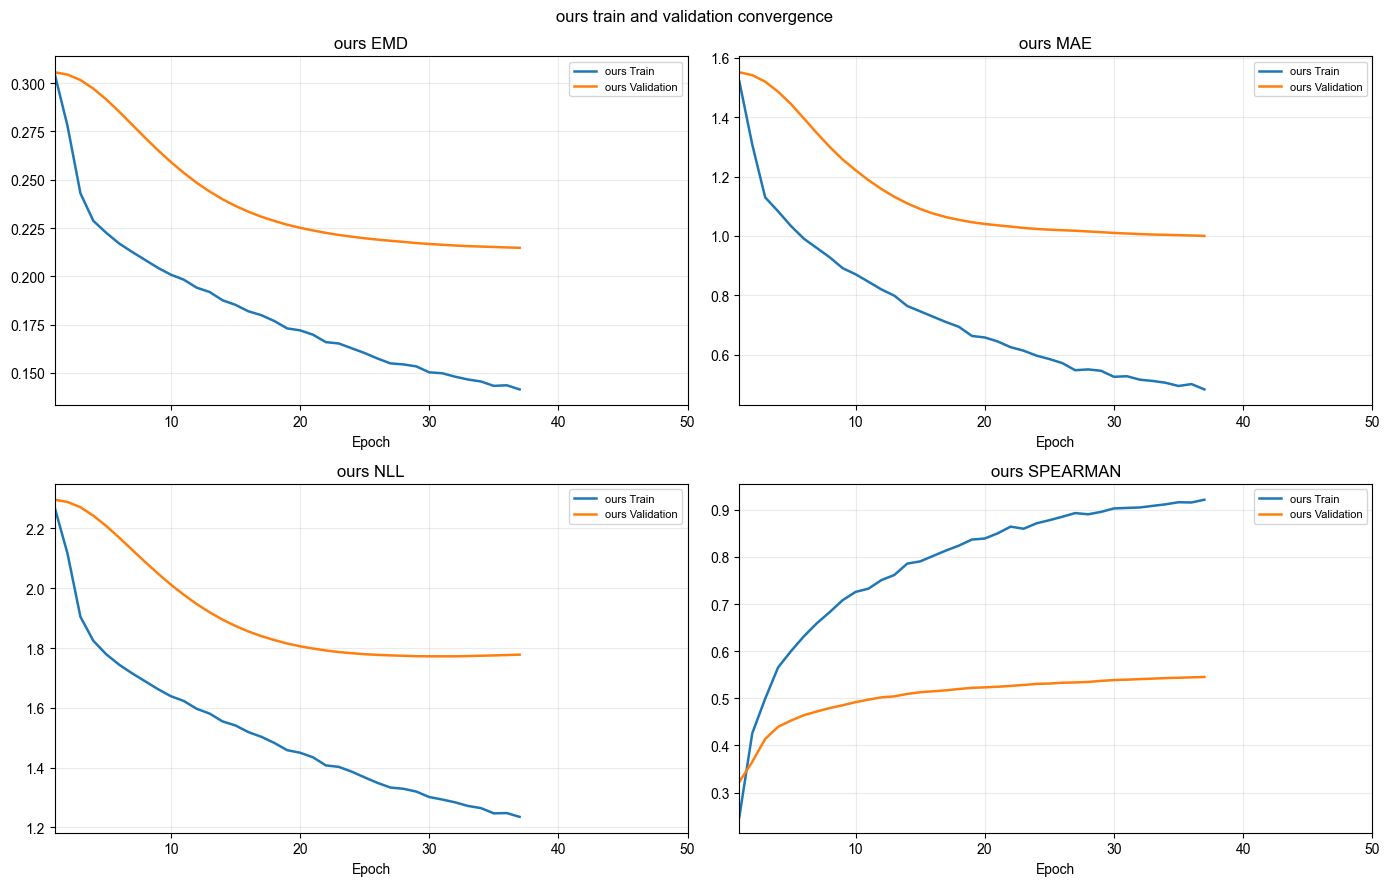

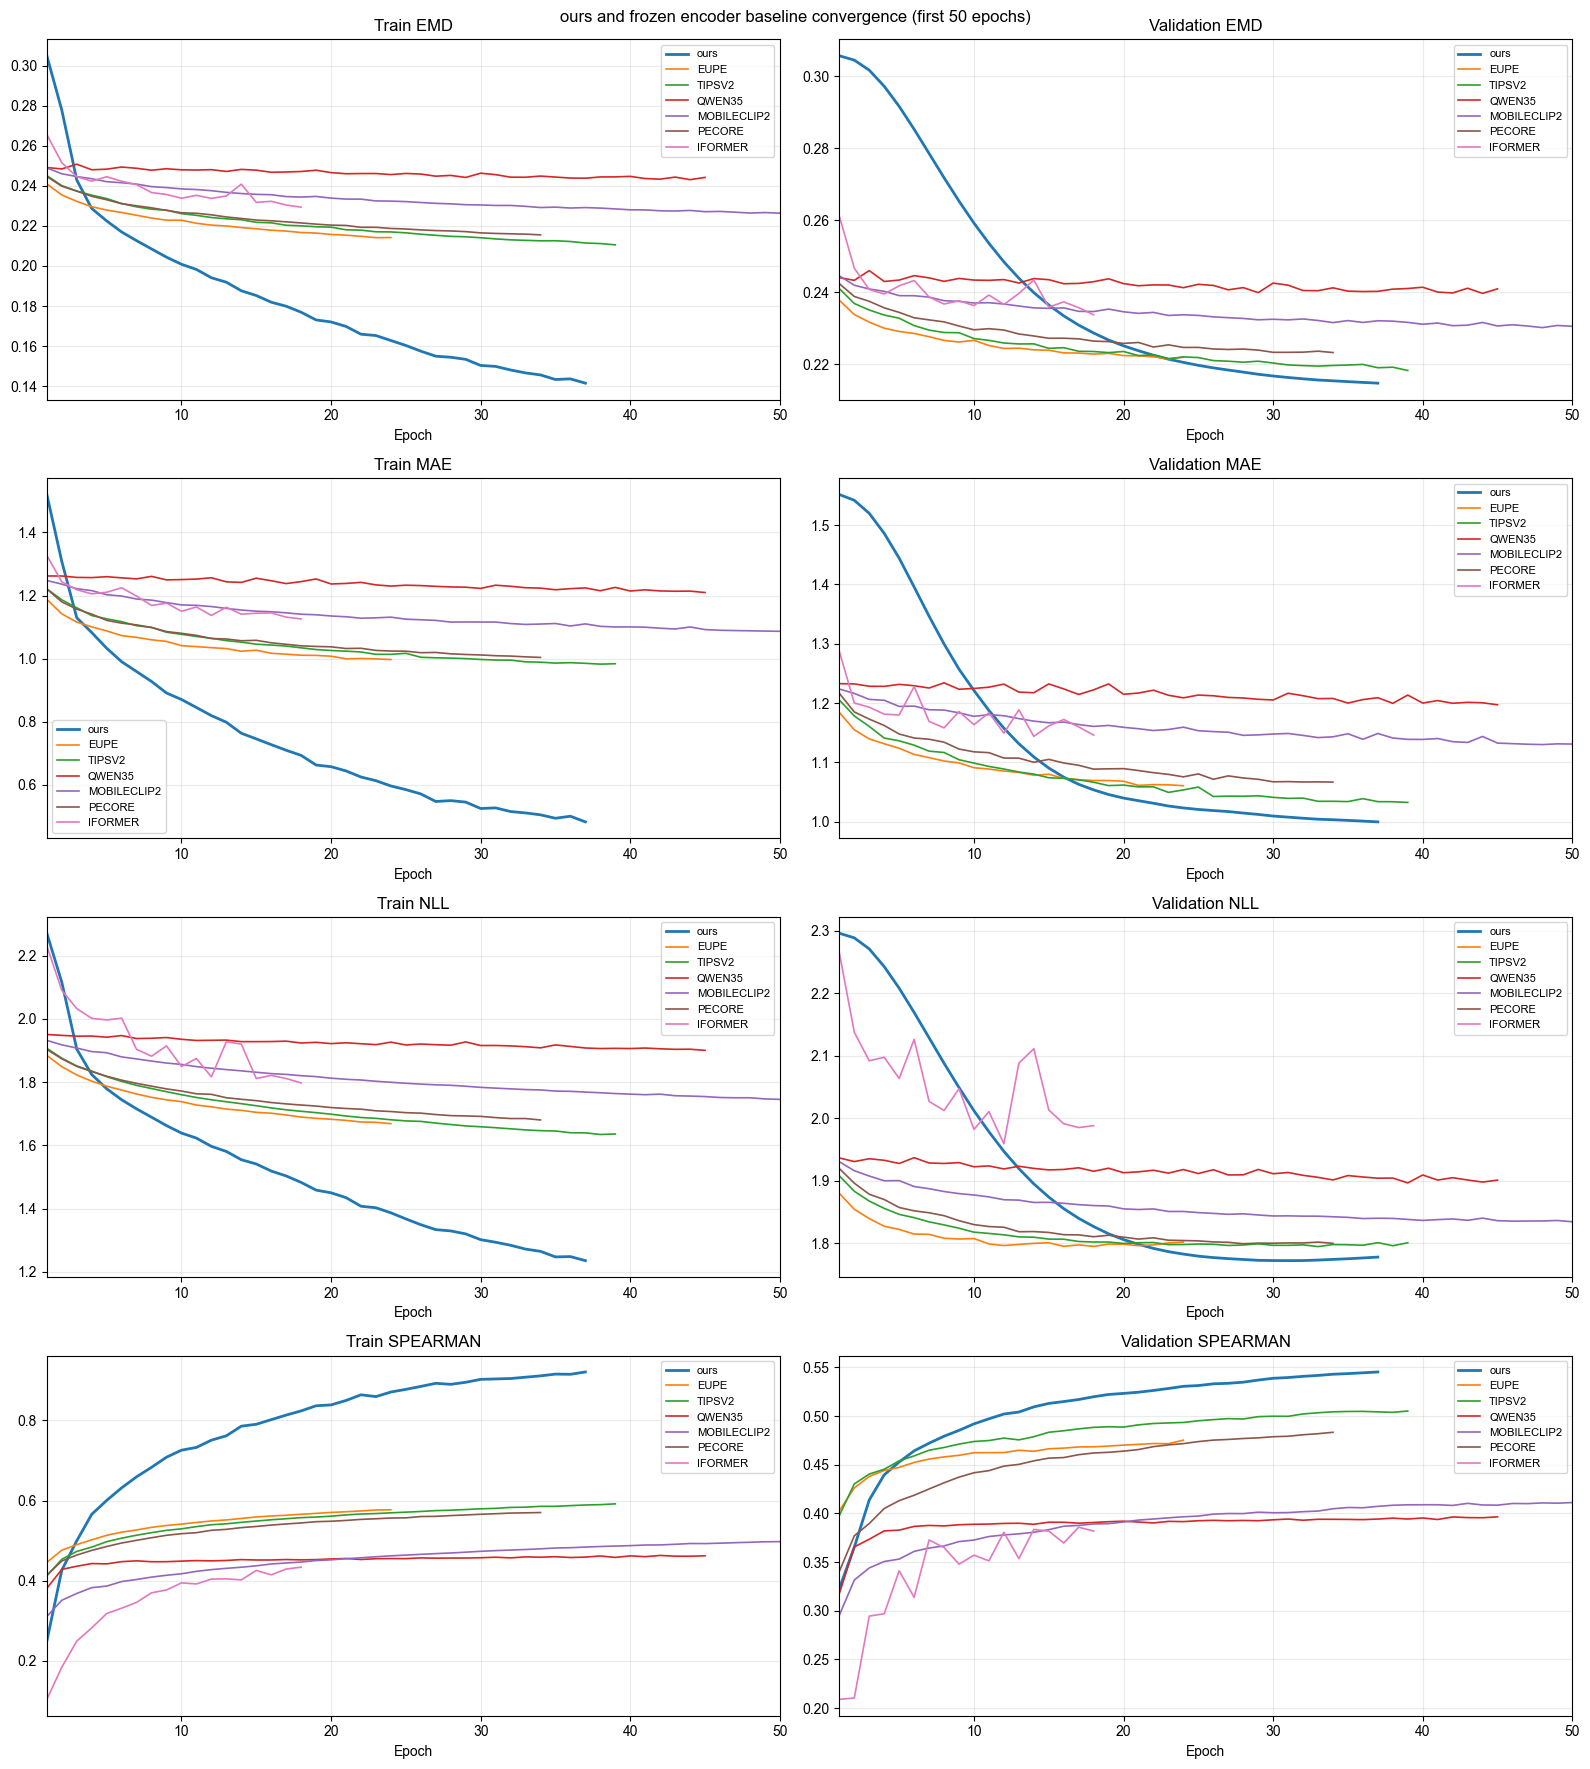

In [15]:
baseline_file=OUTPUT_DIR/'compare_history.csv'
baseline_weights_ready=baseline_file.is_file() and all((WEIGHTS_DIR/f'{method}.pt').is_file() for method in BASELINE_METHODS)
if baseline_weights_ready:
    baseline_frame=pd.read_csv(baseline_file)
    required_baseline_columns=['method','epoch','stop_reason']+[f'{split}_{metric}' for metric in ['emd','mae','nll','spearman'] for split in ('train','val')]
    baseline_weights_ready=all(column in baseline_frame.columns for column in required_baseline_columns) and set(BASELINE_METHODS).issubset(set(baseline_frame['method'].astype(str)))
if baseline_weights_ready:
    print('复用已有六个冻结编码器基线历史和权重:',baseline_file)
else:
    baseline_rows=[]
    for method in BASELINE_METHODS:
        print('开始基线:',method)
        baseline_net=create_baseline(method,pretrained=True,freeze_backbone=True,dropout=0.10).to(device)
        train_features,train_feature_targets=extract_baseline_features(baseline_net,eval_train_dataset)
        val_features,val_feature_targets=extract_baseline_features(baseline_net,val_dataset)
        feature_dataset=TensorDataset(train_features,train_feature_targets)
        feature_loader=DataLoader(feature_dataset,batch_size=BASELINE_BATCH,shuffle=True,num_workers=0,pin_memory=USE_AMP)
        baseline_optimizer=torch.optim.AdamW(baseline_net.head.parameters(),lr=BASELINE_LR,weight_decay=0.01)
        baseline_scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(baseline_optimizer,T_max=BASELINE_EPOCHS,eta_min=BASELINE_LR*0.1)
        best_score=float('inf')
        best_state=None
        baseline_bad_epochs=0
        baseline_best_nll=float('inf')
        baseline_nll_bad_epochs=0
        for epoch in range(1,BASELINE_EPOCHS+1):
            baseline_net.train()
            for features,targets in feature_loader:
                features=features.to(device,non_blocking=True)
                targets=targets.to(device,non_blocking=True)
                baseline_optimizer.zero_grad(set_to_none=True)
                log_probs=baseline_net.forward_from_features(features)
                objective=baseline_objective(log_probs,targets)
                objective.backward()
                torch.nn.utils.clip_grad_norm_(baseline_net.head.parameters(),1.0)
                baseline_optimizer.step()
            train_result=baseline_metrics(baseline_net,train_features,train_feature_targets)
            val_result=baseline_metrics(baseline_net,val_features,val_feature_targets)
            score=select_score(val_result)
            improved=np.isfinite(score) and score<best_score-MIN_DELTA
            if improved:
                best_score=score
                best_state={name:tensor.detach().cpu().clone() for name,tensor in baseline_net.state_dict().items()}
            baseline_bad_epochs=0 if improved else baseline_bad_epochs+1
            nll_improved=np.isfinite(val_result['nll']) and val_result['nll']<baseline_best_nll-MIN_DELTA
            baseline_best_nll=val_result['nll'] if nll_improved else baseline_best_nll
            baseline_nll_bad_epochs=0 if nll_improved else baseline_nll_bad_epochs+1
            stop_reason=''
            if baseline_bad_epochs>=PATIENCE:
                stop_reason='score'
            elif baseline_nll_bad_epochs>=NLL_PATIENCE:
                stop_reason='nll'
            elif epoch>=BASELINE_EPOCHS:
                stop_reason='max_epochs'
            row={'method':method,'epoch':epoch,'lr':baseline_optimizer.param_groups[0]['lr'],'stop_reason':stop_reason}
            row.update({f'train_{key}':value for key,value in train_result.items()})
            row.update({f'val_{key}':value for key,value in val_result.items()})
            baseline_rows.append(row)
            baseline_scheduler.step()
            print(f'{method} Epoch {epoch:02d}/{BASELINE_EPOCHS} | Val EMD={val_result["emd"]:.5f} MAE={val_result["mae"]:.4f} NLL={val_result["nll"]:.4f} Spearman={val_result["spearman"]:.4f} | wait={baseline_bad_epochs}/{PATIENCE} nll_wait={baseline_nll_bad_epochs}/{NLL_PATIENCE}')
            if stop_reason:
                print(f'{method} Early stopping: {stop_reason}')
                break
        if best_state is not None:
            torch.save(best_state,WEIGHTS_DIR/f'{method}.pt')
        del baseline_net,train_features,train_feature_targets,val_features,val_feature_targets,feature_dataset,feature_loader
        if device.type=='cuda':
            torch.cuda.empty_cache()
    baseline_frame=pd.DataFrame.from_records(baseline_rows)
    baseline_frame.to_csv(baseline_file,index=False,encoding='utf-8-sig')
    print('六个基线历史已保存:',baseline_file)

history_frame=pd.read_csv(OUTPUT_DIR/'history.csv').sort_values('epoch')
required_metrics=['emd','mae','nll','spearman']
for metric in required_metrics:
    for split in ('train','val'):
        if f'{split}_{metric}' not in history_frame.columns:
            raise RuntimeError(f'ours history缺少: {split}_{metric}')
if 'method' not in baseline_frame.columns:
    raise RuntimeError(f'{OUTPUT_DIR}/compare_history.csv缺少method列')
missing_methods=[method for method in BASELINE_METHODS if method not in set(baseline_frame['method'].astype(str))]
if missing_methods:
    raise RuntimeError(f'compare_history.csv缺少方法: {missing_methods}')
for method in BASELINE_METHODS:
    subset=baseline_frame.loc[baseline_frame['method'].astype(str)==method]
    for metric in required_metrics:
        for split in ('train','val'):
            if f'{split}_{metric}' not in subset.columns:
                raise RuntimeError(f'{method}缺少{split}_{metric}')
plot_history_frame=history_frame.loc[history_frame['epoch']<=PLOT_EPOCHS].copy()
fig,axs=plt.subplots(2,2,figsize=(14,9))
for ax,metric in zip(axs.ravel(),required_metrics):
    ax.plot(plot_history_frame['epoch'],plot_history_frame[f'train_{metric}'],label='ours Train',linewidth=1.8)
    ax.plot(plot_history_frame['epoch'],plot_history_frame[f'val_{metric}'],label='ours Validation',linewidth=1.8)
    ax.set_title(f'ours {metric.upper()}')
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.25)
    ax.set_xlim(1,PLOT_EPOCHS)
    ax.legend(fontsize=8)
fig.suptitle('ours train and validation convergence')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'convergence.png',dpi=200,bbox_inches='tight')
plt.show()
series={'ours':history_frame}
for method in BASELINE_METHODS:
    series[method]=baseline_frame.loc[baseline_frame['method'].astype(str)==method].sort_values('epoch')
plot_series={name:table.loc[table['epoch']<=PLOT_EPOCHS].copy() for name,table in series.items()}
fig,axs=plt.subplots(4,2,figsize=(16,18))
for row_index,metric in enumerate(required_metrics):
    for name,table in plot_series.items():
        axs[row_index,0].plot(table['epoch'],table[f'train_{metric}'],label=name,linewidth=2 if name=='ours' else 1.2)
        axs[row_index,1].plot(table['epoch'],table[f'val_{metric}'],label=name,linewidth=2 if name=='ours' else 1.2)
    axs[row_index,0].set_title(f'Train {metric.upper()}')
    axs[row_index,1].set_title(f'Validation {metric.upper()}')
    axs[row_index,0].set_xlabel('Epoch')
    axs[row_index,1].set_xlabel('Epoch')
    axs[row_index,0].grid(alpha=0.25)
    axs[row_index,1].grid(alpha=0.25)
    axs[row_index,0].set_xlim(1,PLOT_EPOCHS)
    axs[row_index,1].set_xlim(1,PLOT_EPOCHS)
    axs[row_index,0].legend(fontsize=8)
    axs[row_index,1].legend(fontsize=8)
fig.suptitle('ours and frozen encoder baseline convergence (first 50 epochs)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'comparison.png',dpi=200,bbox_inches='tight')
plt.show()


## 8. 最佳验证指标


In [16]:
comparison=[]
for name,table in series.items():
    table=table.dropna(subset=['val_emd']).sort_values('epoch')
    if name=='ours':
        selected_epoch=int(pd.read_csv(OUTPUT_DIR/'best_metrics.csv').iloc[0]['epoch'])
        row=table.loc[table['epoch']==selected_epoch].iloc[0]
    else:
        row=table.loc[table['val_emd'].idxmin()]
    comparison.append({'model':name,'epoch':int(row['epoch']),'emd':float(row['val_emd']),'mae':float(row['val_mae']),'nll':float(row['val_nll']),'spearman':float(row['val_spearman'])})
result_table=pd.DataFrame.from_records(comparison).sort_values('emd')
print(result_table.to_string(index=False,float_format=lambda value:f'{value:.5f}'))
print('ours checkpoint:',WEIGHTS_DIR/'ours.pt')


      model  epoch     emd     mae     nll  spearman
       ours     37 0.21476 0.99993 1.77784   0.54531
     TIPSV2     39 0.21828 1.03271 1.80073   0.50520
       EUPE     23 0.22148 1.06239 1.80046   0.47165
     PECORE     34 0.22327 1.06700 1.79986   0.48336
MOBILECLIP2     59 0.22933 1.12571 1.83249   0.41350
    IFORMER     18 0.23375 1.14613 1.98803   0.38191
     QWEN35     44 0.23968 1.20060 1.89783   0.39560
ours checkpoint: D:\MyJupyter\Works\FaceScore\weights\ours.pt


## 9. 固定验证集预测
预测保存到 outputs/recent_compare/predictions.npz。


In [17]:
student.load_state_dict(torch.load(WEIGHTS_DIR/'ours.pt',map_location=device,weights_only=True),strict=True)
student.eval()
all_predictions=[]
all_labels=[]
with torch.inference_mode():
    for batch in val_loader:
        x=batch[0].to(device,non_blocking=True)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            result=student(x)
        all_predictions.append(result.float().exp().cpu().numpy())
        all_labels.append(batch[1].float().cpu().numpy())
val_probabilities=np.concatenate(all_predictions,axis=0)
val_labels=np.concatenate(all_labels,axis=0)
val_rating_counts=np.asarray([len(parse_scores(base_dataset.image_paths[idx])) for idx in val_ids],dtype=np.int32)
val_file_names=np.asarray([image_names[idx] for idx in val_ids])
np.savez_compressed(OUTPUT_DIR/'predictions.npz',probs=val_probabilities,labels=val_labels,n_ratings=val_rating_counts,file_names=val_file_names)
group_rows=[]
for title,mask in [('1_rater',val_rating_counts==1),('2_or_more',val_rating_counts>=2),('3_or_more',val_rating_counts>=3),('all',np.ones(len(val_rating_counts),dtype=bool))]:
    if mask.sum()>=4:
        result=compute_metrics(val_probabilities[mask],val_labels[mask])
        group_rows.append({'group':title,'n_photos':int(mask.sum()),**result})
group_table=pd.DataFrame.from_records(group_rows)
pred_bins=np.arange(1,11,dtype=np.float64)
pred_mean=val_probabilities@pred_bins
target_mean=val_labels@pred_bins
pred_entropy=-(val_probabilities*np.log(np.maximum(val_probabilities,1e-12))).sum(axis=1)
print(group_table.to_string(index=False,float_format=lambda value:f'{value:.5f}'))
print({'pred_entropy_mean':float(pred_entropy.mean()),'target_entropy_mean':float((-(val_labels*np.log(np.maximum(val_labels,1e-12))).sum(axis=1)).mean()),'pred_mean_std':float(pred_mean.std()),'target_mean_std':float(target_mean.std()),'pred_tail_mass_at_8':float(val_probabilities[:,7:].sum(axis=1).mean()),'target_tail_mass_at_8':float(val_labels[:,7:].sum(axis=1).mean())})


    group  n_photos     emd     mae     nll  spearman
  1_rater       106 0.25534 1.12309 1.66249   0.51520
2_or_more       154 0.18684 0.91515 1.85723   0.56694
3_or_more       102 0.18744 0.93634 1.87907   0.55593
      all       260 0.21476 0.99993 1.77784   0.54531
{'pred_entropy_mean': 1.6964364051818848, 'target_entropy_mean': 0.4854658246040344, 'pred_mean_std': 0.9116807975335195, 'target_mean_std': 1.6599799172310956, 'pred_tail_mass_at_8': 0.05594216287136078, 'target_tail_mass_at_8': 0.055859968066215515}


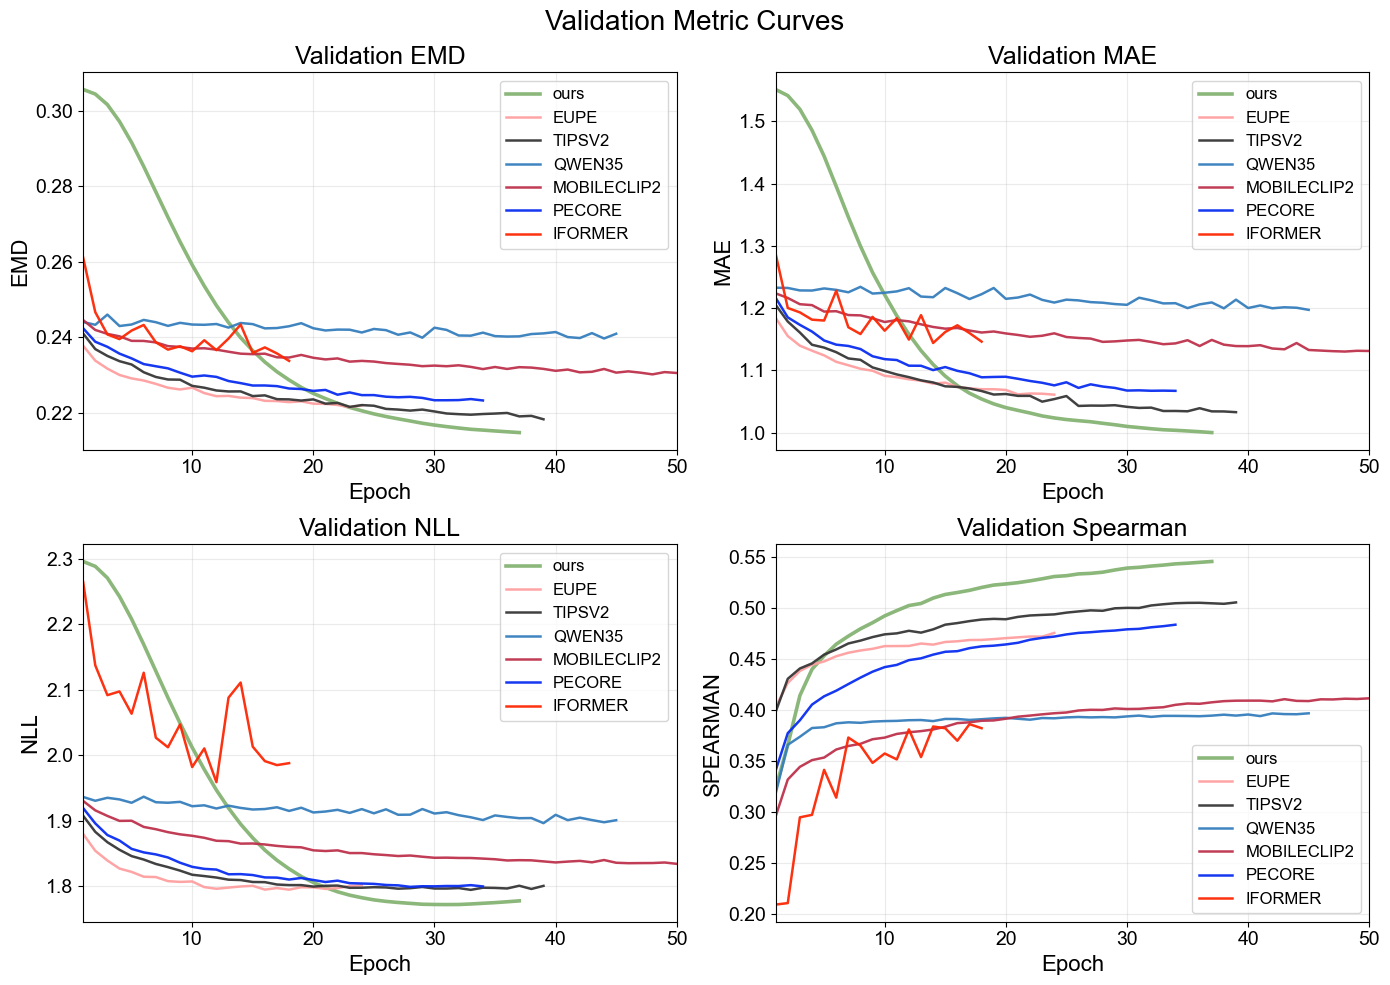

图像已保存到: D:\MyJupyter\Works\FaceScore\outputs\figures\validation_metric_curves.pdf


In [18]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
OUTPUT_DIR=ROOT_DIR/'outputs'/'recent_compare'
FIGURE_DIR=ROOT_DIR/'outputs'/'figures'
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
MAX_EPOCH=50
TITLE_SIZE=18
LABEL_SIZE=16
TICK_SIZE=14
LEGEND_SIZE=12
SUPTITLE_SIZE=20
METHODS=['ours','EUPE','TIPSV2','QWEN35','MOBILECLIP2','PECORE','IFORMER']
COLORS={'ours':'#85B373','EUPE':'#FF9FA0','TIPSV2':'#373737','QWEN35':'#367FBD','MOBILECLIP2':'#BD324C','PECORE':'#092DF1','IFORMER':'#FC2704'}
METRICS=['emd','mae','nll','spearman']
METRIC_TITLES={'emd':'Validation EMD','mae':'Validation MAE','nll':'Validation NLL','spearman':'Validation Spearman'}
ours_history=pd.read_csv(OUTPUT_DIR/'history.csv')
ours_history.insert(0,'method','ours')
baseline_history=pd.read_csv(OUTPUT_DIR/'compare_history.csv')
history=pd.concat([ours_history,baseline_history],ignore_index=True)
history['method']=history['method'].astype(str)
history=history.loc[history['method'].isin(METHODS)].copy()
history=history.loc[history['epoch']<=MAX_EPOCH].copy()
plt.rcParams['font.family']='Arial'
plt.rcParams['font.sans-serif']=['Arial']
plt.rcParams['axes.unicode_minus']=False
fig,axes=plt.subplots(2,2,figsize=(14,10))
for axis,metric in zip(axes.ravel(),METRICS):
    for method in METHODS:
        method_history=history.loc[history['method']==method].sort_values('epoch')
        if method_history.empty:
            continue
        axis.plot(method_history['epoch'],method_history[f'val_{metric}'],label=method,color=COLORS[method],linewidth=2.6 if method=='ours' else 1.8,alpha=0.95)
    axis.set_title(METRIC_TITLES[metric],fontsize=TITLE_SIZE,fontfamily='Arial')
    axis.set_xlabel('Epoch',fontsize=LABEL_SIZE,fontfamily='Arial')
    axis.set_ylabel(metric.upper(),fontsize=LABEL_SIZE,fontfamily='Arial')
    axis.tick_params(axis='both',labelsize=TICK_SIZE)
    axis.grid(alpha=0.25,linewidth=0.8)
    axis.legend(fontsize=LEGEND_SIZE,frameon=True)
    axis.set_xlim(1,MAX_EPOCH)
fig.suptitle('Validation Metric Curves',fontsize=SUPTITLE_SIZE,fontfamily='Arial')
fig.tight_layout()
figure_path=FIGURE_DIR/'validation_metric_curves.pdf'
fig.savefig(figure_path,dpi=600,bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'图像已保存到: {figure_path}')

In [19]:

import gc
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader,TensorDataset
SEEDS=[42,123,2026,3407,777]
REPEAT_METHODS=['ours','EUPE','TIPSV2','QWEN35','MOBILECLIP2','PECORE','IFORMER']
SKIP_EXISTING=True
SEED_METRICS_PATH=OUTPUT_DIR/'seed_best_metrics.csv'
required_names=['device','USE_AMP','WEIGHTS_DIR','OUTPUT_DIR','train_feature_values','val_feature_values','train_targets','val_targets','train_counts','prior','tip_adapter','train_loader','val_loader','train_epoch','evaluate_epoch','loss_fn','TrainableEMA','save_model','select_score','BASELINE_BATCH','BASELINE_LR','BASELINE_EPOCHS','EPOCHS','PATIENCE','NLL_PATIENCE','MIN_DELTA','LEARNING_RATE','WARMUP_EPOCHS','WEIGHT_DECAY','EMA_DECAY','GRAD_CLIP','BASE_CONCENTRATION','eval_train_dataset','val_dataset','extract_baseline_features','baseline_objective','baseline_metrics','compute_metrics','SparseLandauScoreField','create_baseline','CountDataset']
missing_names=[name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(f'请先执行train_compare.ipynb前面的训练准备单元格，缺少变量: {missing_names}')
if len(train_feature_values)!=2335 or len(val_feature_values)!=260:
    raise RuntimeError('当前缓存特征数量不是2335/260，请检查固定数据划分')
if not isinstance(train_loader.dataset,CountDataset) or not isinstance(train_loader.dataset.dataset,TensorDataset):
    raise RuntimeError('当前train_loader不是冻结特征训练集')
WEIGHTS_DIR.mkdir(parents=True,exist_ok=True)
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
def reset_repeat_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
def record_seed_result(record):
    new_frame=pd.DataFrame([record])
    if SEED_METRICS_PATH.is_file():
        previous=pd.read_csv(SEED_METRICS_PATH)
        new_frame=pd.concat([previous,new_frame],ignore_index=True)
        new_frame=new_frame.drop_duplicates(subset=['method','seed'],keep='last')
    new_frame.to_csv(SEED_METRICS_PATH,index=False,encoding='utf-8-sig')
def make_ours_optimizer(net):
    decay_parameters=[]
    no_decay_parameters=[]
    prediction_decay_parameters=[]
    prediction_no_decay_parameters=[]
    for name,param in net.named_parameters():
        if not param.requires_grad:
            continue
        is_prediction=any(key in name.lower() for key in ('head','evidence','global_projection','global_gate'))
        is_no_decay=param.ndim<2 or any(key in name.lower() for key in ('bias','norm','source_scale','source_bias','scale_logits','entropy_log_scale','evidence_gate','local_evidence_logit','global_gate'))
        if is_prediction and is_no_decay:
            prediction_no_decay_parameters.append(param)
        elif is_prediction:
            prediction_decay_parameters.append(param)
        elif is_no_decay:
            no_decay_parameters.append(param)
        else:
            decay_parameters.append(param)
    return torch.optim.AdamW([{'params':decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':WEIGHT_DECAY},{'params':no_decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':0.0},{'params':prediction_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':WEIGHT_DECAY*0.5},{'params':prediction_no_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':0.0}],lr=LEARNING_RATE)
def ours_schedule_lambda(epoch):
    if epoch<WARMUP_EPOCHS:
        return 0.3+0.7*(epoch+1)/WARMUP_EPOCHS
    schedule_horizon=min(EPOCHS,60)
    progress=min(1.0,(epoch-WARMUP_EPOCHS+1)/max(1,schedule_horizon-WARMUP_EPOCHS))
    return (1e-4/LEARNING_RATE)+(1.0-1e-4/LEARNING_RATE)*0.5*(1.0+np.cos(np.pi*progress))
def train_ours_repeat(seed,checkpoint_path):
    reset_repeat_seed(seed)
    net=SparseLandauScoreField(pretrained=False,backbone=tip_adapter,dropout=0.10,train_last_stage=False,width=24,prior_mix=0.0,use_entropy=False,use_high_resolution=False,scales=(224,),grid_side=16,use_evidence_head=True,evidence_base=BASE_CONCENTRATION,use_global_token=True).to(device)
    with torch.no_grad():
        net.mean.copy_(tip_adapter.mean)
        net.std.copy_(tip_adapter.std)
    net.set_feature_stats(train_feature_values.mean(dim=0),train_feature_values.std(dim=0))
    net.set_prior(prior)
    optimizer=make_ours_optimizer(net)
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda=ours_schedule_lambda)
    scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP) if device.type=='cuda' else None
    ema=TrainableEMA(net,decay=EMA_DECAY)
    best_score=float('inf')
    best_nll=float('inf')
    bad_epochs=0
    nll_bad_epochs=0
    best_epoch=0
    best_metrics=None
    best_parameters=None
    stop_reason='max_epochs'
    for epoch in range(1,EPOCHS+1):
        train_result=train_epoch(net,optimizer,scaler,ema)
        ema.apply(net)
        try:
            val_result=evaluate_epoch(net)
            score=select_score(val_result)
            improved=np.isfinite(score) and score<best_score-MIN_DELTA
            if improved:
                best_score=score
                best_epoch=epoch
                best_metrics=val_result.copy()
                best_parameters={name:param.detach().cpu().clone() for name,param in net.named_parameters() if param.requires_grad}
        finally:
            ema.restore(net)
        bad_epochs=0 if improved else bad_epochs+1
        nll_improved=np.isfinite(val_result['nll']) and val_result['nll']<best_nll-MIN_DELTA
        best_nll=val_result['nll'] if nll_improved else best_nll
        nll_bad_epochs=0 if nll_improved else nll_bad_epochs+1
        scheduler.step()
        if bad_epochs>=PATIENCE:
            stop_reason='score_patience'
        elif nll_bad_epochs>=NLL_PATIENCE:
            stop_reason='nll_patience'
        if epoch==1 or epoch%5==0 or stop_reason!='max_epochs':
            print(f'ours seed={seed} epoch={epoch:03d} val_emd={val_result["emd"]:.5f} val_mae={val_result["mae"]:.5f} val_nll={val_result["nll"]:.5f} val_spearman={val_result["spearman"]:.4f} best={best_epoch}',flush=True)
        if stop_reason!='max_epochs':
            break
    if best_parameters is None:
        raise RuntimeError(f'ours seed={seed}没有产生有效的最佳权重')
    with torch.no_grad():
        for name,param in net.named_parameters():
            if name in best_parameters:
                param.copy_(best_parameters[name].to(device=param.device,dtype=param.dtype))
    save_model(net,checkpoint_path)
    record={'method':'ours','seed':seed,'best_epoch':best_epoch,'stop_epoch':epoch,'stop_reason':stop_reason,'checkpoint':checkpoint_path.name,'balanced':best_score,**{f'val_{key}':value for key,value in best_metrics.items()}}
    del net,optimizer,scheduler,scaler,ema,best_parameters
    gc.collect()
    if device.type=='cuda':
        torch.cuda.empty_cache()
    return record
def train_baseline_repeat(method,net,features,targets,val_features,val_labels,seed,checkpoint_path):
    reset_repeat_seed(seed)
    for layer in net.head.modules():
        if isinstance(layer,torch.nn.Linear):
            layer.reset_parameters()
    feature_loader=DataLoader(TensorDataset(features,targets),batch_size=BASELINE_BATCH,shuffle=True,num_workers=0,pin_memory=USE_AMP)
    optimizer=torch.optim.AdamW(net.head.parameters(),lr=BASELINE_LR,weight_decay=0.01)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=BASELINE_EPOCHS,eta_min=BASELINE_LR*0.1)
    best_score=float('inf')
    best_nll=float('inf')
    bad_epochs=0
    nll_bad_epochs=0
    best_epoch=0
    best_metrics=None
    best_head=None
    stop_reason='max_epochs'
    for epoch in range(1,BASELINE_EPOCHS+1):
        net.train()
        for feature_batch,target_batch in feature_loader:
            feature_batch=feature_batch.to(device,non_blocking=True)
            target_batch=target_batch.to(device,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            log_probs=net.forward_from_features(feature_batch)
            loss=baseline_objective(log_probs,target_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.head.parameters(),1.0)
            optimizer.step()
        val_result=baseline_metrics(net,val_features,val_labels)
        score=select_score(val_result)
        improved=np.isfinite(score) and score<best_score-MIN_DELTA
        if improved:
            best_score=score
            best_epoch=epoch
            best_metrics=val_result.copy()
            best_head={name:tensor.detach().cpu().clone() for name,tensor in net.head.state_dict().items()}
        bad_epochs=0 if improved else bad_epochs+1
        nll_improved=np.isfinite(val_result['nll']) and val_result['nll']<best_nll-MIN_DELTA
        best_nll=val_result['nll'] if nll_improved else best_nll
        nll_bad_epochs=0 if nll_improved else nll_bad_epochs+1
        if bad_epochs>=PATIENCE:
            stop_reason='score_patience'
        elif nll_bad_epochs>=NLL_PATIENCE:
            stop_reason='nll_patience'
        scheduler.step()
        if epoch==1 or epoch%5==0 or stop_reason!='max_epochs':
            print(f'{method} seed={seed} epoch={epoch:03d} val_emd={val_result["emd"]:.5f} val_mae={val_result["mae"]:.5f} val_nll={val_result["nll"]:.5f} val_spearman={val_result["spearman"]:.4f} best={best_epoch}',flush=True)
        if stop_reason!='max_epochs':
            break
    if best_head is None:
        raise RuntimeError(f'{method} seed={seed}没有产生有效的最佳权重')
    net.head.load_state_dict(best_head,strict=True)
    save_model(net,checkpoint_path)
    record={'method':method,'seed':seed,'best_epoch':best_epoch,'stop_epoch':epoch,'stop_reason':stop_reason,'checkpoint':checkpoint_path.name,'balanced':best_score,**{f'val_{key}':value for key,value in best_metrics.items()}}
    del optimizer,scheduler,feature_loader,best_head
    return record
for method in REPEAT_METHODS:
    pending=[seed for seed in SEEDS if not (WEIGHTS_DIR/f'{method}_{seed}.pt').is_file()]
    if SKIP_EXISTING:
        for seed in SEEDS:
            if seed not in pending:
                print(f'跳过已存在权重: {method}_{seed}.pt')
    elif len(pending)!=len(SEEDS):
        raise FileExistsError(f'{method}已有种子权重，为保护现有权重不会覆盖；设置SKIP_EXISTING=True即可跳过')
    if not pending:
        continue
    if method=='ours':
        for seed in pending:
            checkpoint_path=WEIGHTS_DIR/f'ours_{seed}.pt'
            record=train_ours_repeat(seed,checkpoint_path)
            record_seed_result(record)
            print(f'完成: {checkpoint_path.name} | 最佳Epoch={record["best_epoch"]}',flush=True)
        continue
    reference_path=WEIGHTS_DIR/f'{method}.pt'
    if not reference_path.is_file():
        raise FileNotFoundError(f'缺少基线完整权重: {reference_path}')
    baseline_net=create_baseline(method,pretrained=False,freeze_backbone=True,dropout=0.10)
    baseline_net.load_state_dict(torch.load(reference_path,map_location='cpu',weights_only=True),strict=True)
    baseline_net=baseline_net.to(device).eval()
    train_features,train_labels=extract_baseline_features(baseline_net,eval_train_dataset)
    val_features,val_labels=extract_baseline_features(baseline_net,val_dataset)
    if not torch.allclose(train_labels,train_targets,atol=1e-6) or not torch.allclose(val_labels,val_targets,atol=1e-6):
        raise RuntimeError(f'{method}的特征缓存与固定划分标签不一致')
    for seed in pending:
        checkpoint_path=WEIGHTS_DIR/f'{method}_{seed}.pt'
        record=train_baseline_repeat(method,baseline_net,train_features,train_labels,val_features,val_labels,seed,checkpoint_path)
        record_seed_result(record)
        print(f'完成: {checkpoint_path.name} | 最佳Epoch={record["best_epoch"]}',flush=True)
    del baseline_net,train_features,train_labels,val_features,val_labels
    gc.collect()
    if device.type=='cuda':
        torch.cuda.empty_cache()
print(f'全部种子训练结束。权重目录: {WEIGHTS_DIR}')
print(f'最佳Epoch记录: {SEED_METRICS_PATH}')


ours seed=42 epoch=001 val_emd=0.30566 val_mae=1.55142 val_nll=2.29604 val_spearman=0.2362 best=1
ours seed=42 epoch=005 val_emd=0.29231 val_mae=1.44637 val_nll=2.21327 val_spearman=0.4232 best=5
ours seed=42 epoch=010 val_emd=0.26053 val_mae=1.22697 val_nll=2.01917 val_spearman=0.4810 best=10
ours seed=42 epoch=015 val_emd=0.23766 val_mae=1.09581 val_nll=1.88035 val_spearman=0.5070 best=15
ours seed=42 epoch=020 val_emd=0.22551 val_mae=1.04033 val_nll=1.80795 val_spearman=0.5194 best=20
ours seed=42 epoch=025 val_emd=0.21972 val_mae=1.01966 val_nll=1.78040 val_spearman=0.5232 best=25
ours seed=42 epoch=030 val_emd=0.21679 val_mae=1.00680 val_nll=1.77493 val_spearman=0.5250 best=30
ours seed=42 epoch=035 val_emd=0.21536 val_mae=1.00187 val_nll=1.78097 val_spearman=0.5239 best=34
完成: ours_42.pt | 最佳Epoch=34
ours seed=123 epoch=001 val_emd=0.30567 val_mae=1.55165 val_nll=2.29598 val_spearman=0.2752 best=1
ours seed=123 epoch=005 val_emd=0.29192 val_mae=1.44701 val_nll=2.20982 val_spearma